<a href="https://colab.research.google.com/github/JoshEliell/ColabFiles/blob/main/Pr%C3%A1ctica_Validaci%C3%B3n%2C_Evaluaci%C3%B3n_y_Selecci%C3%B3n_274705.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Validación, Evaluación y Selección
---


## Datos del Estudiante

*   Apellidos y Nombre: Victor Joshua Hernandez Ramom
*   Matrícula: 274705

---


In [24]:
# 1. Carga de Bibliotecas y Conjunto de Datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer, f1_score, accuracy_score

from google.colab import drive
drive.mount('/content/drive')

# Cargar el conjunto de datos
info_path = '/content/drive/MyDrive/ClassFiles/TCGA_InfoWithGrade.csv'
df = pd.read_csv(info_path)

# Separar características (X) y variable objetivo (y)
X = df.drop(columns=['Grade'])
y = df['Grade']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Forma del dataset: (839, 23)

Estructura de los datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            839 non-null    int64  
 1   Age_at_diagnosis  839 non-null    float64
 2   Race              839 non-null    int64  
 3   IDH1              839 non-null    int64  
 4   TP53              839 non-null    int64  
 5   ATRX              839 non-null    int64  
 6   PTEN              839 non-null    int64  
 7   EGFR              839 non-null    int64  
 8   CIC               839 non-null    int64  
 9   MUC16             839 non-null    int64  
 10  PIK3CA            839 non-null    int64  
 11  NF1               839 non-null    int64  
 12  PIK3R1            839 non-null    int64  
 13  FUBP1             839 non-null    int64  
 14  RB1               839 non-null    int64  
 15  NOTCH1            839 non-null    in

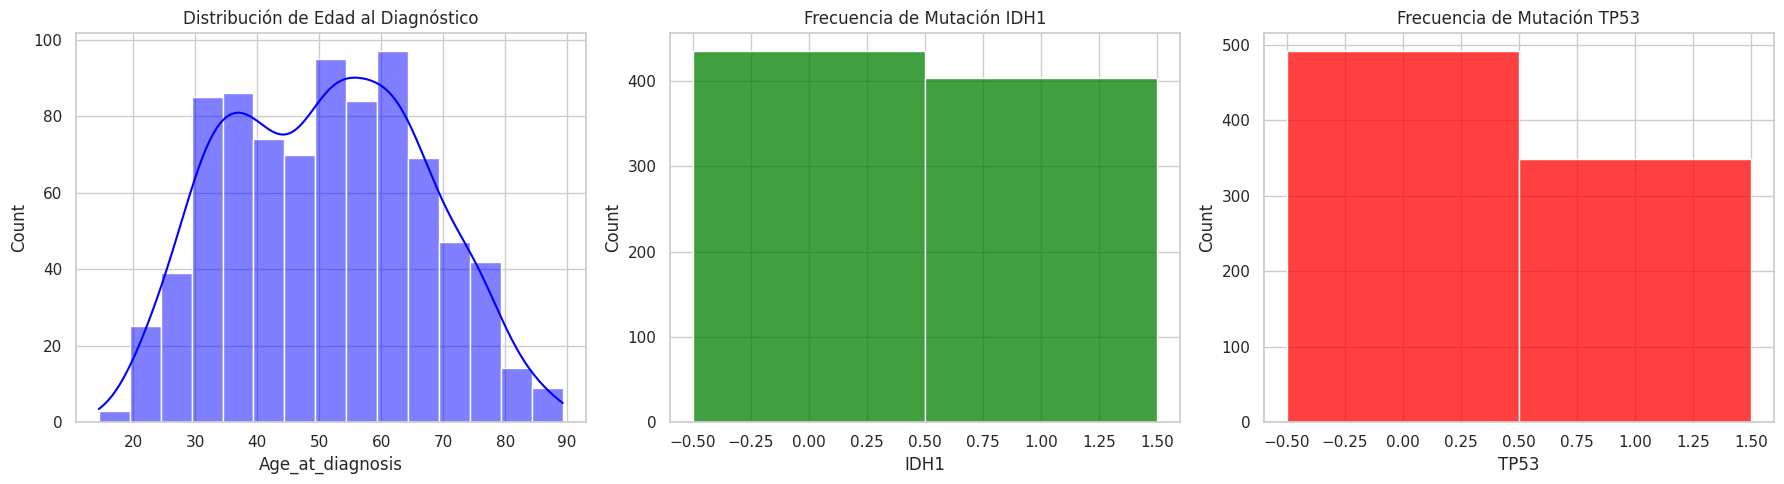

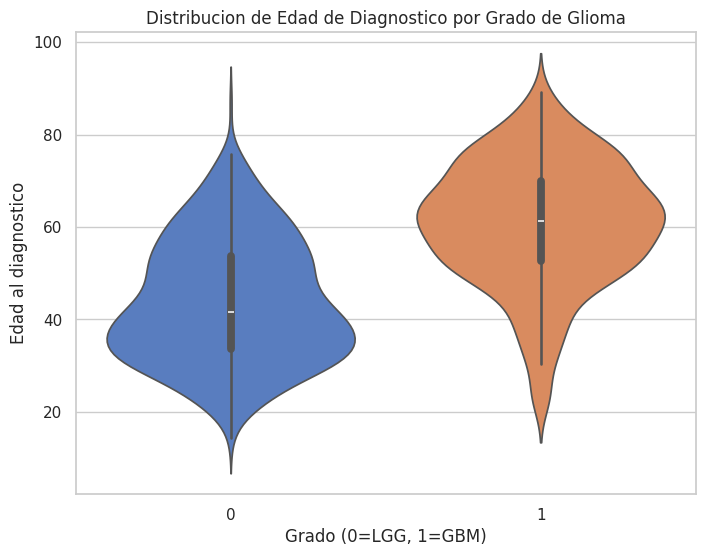

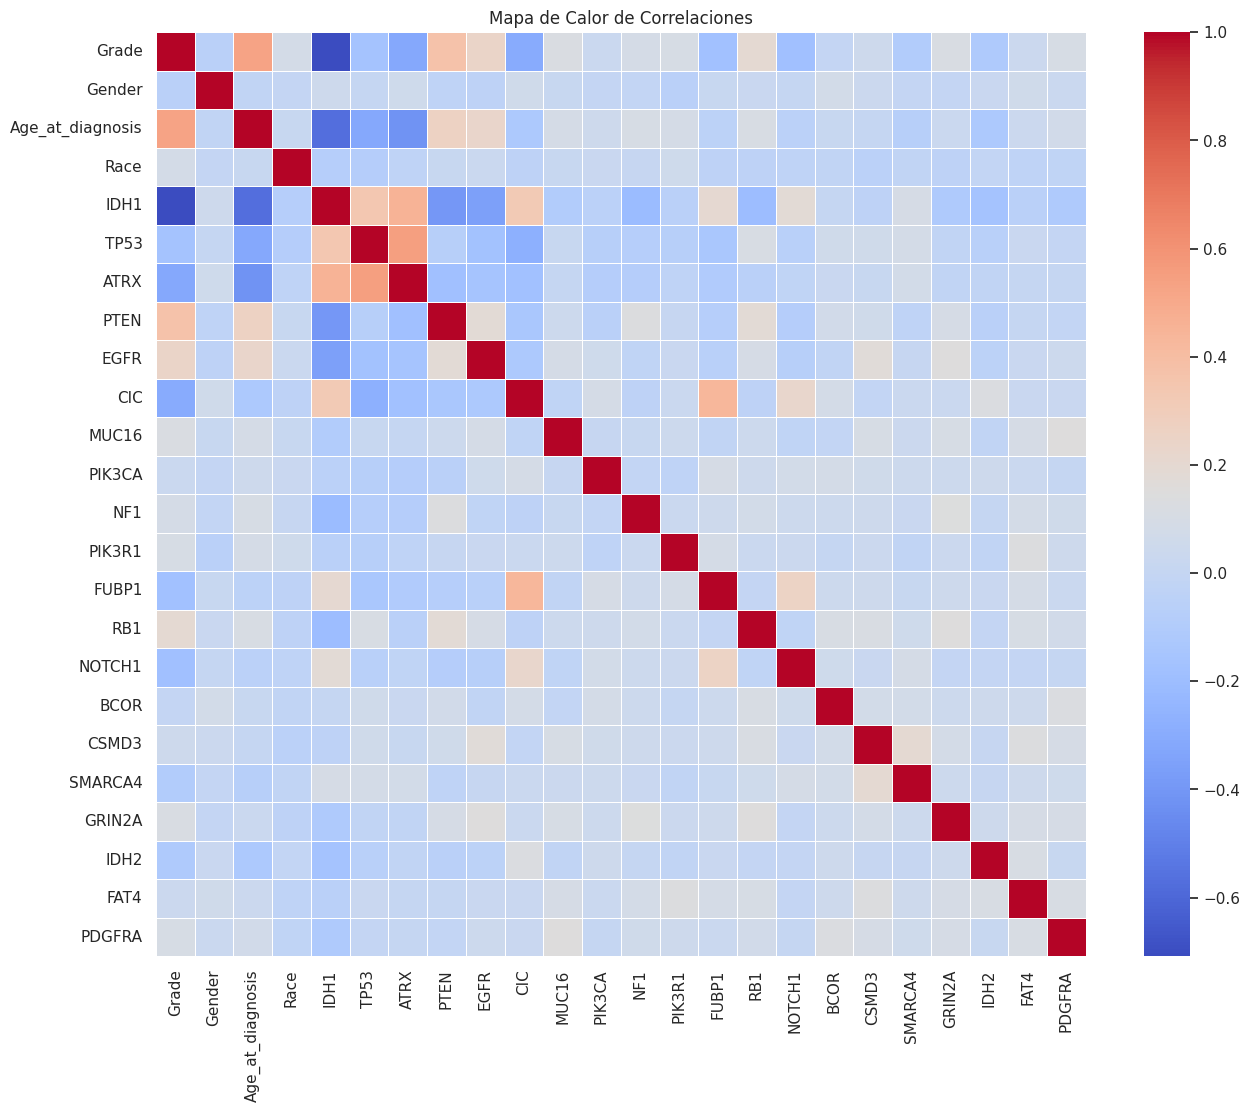

In [25]:
# 2. Análisis exploratorio de datos (EDA)
# Describir forma y estructura
print("Forma del dataset:", X.shape)
print("\nEstructura de los datos:")
print(X.info())
print("\nEstadisticas descriptivas:")
print(X.describe())

# Distribución de clases
print("\nDistribución de clases (Target: Grade):")
print(y.value_counts())

# Visualizar
sns.set_theme(style="whitegrid")

# 1. Histograma de 3 variables numéricas (Edad, IDH1, TP53)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(X['Age_at_diagnosis'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribución de Edad al Diagnóstico')

sns.histplot(X['IDH1'], discrete=True, ax=axes[1], color='green')
axes[1].set_title('Frecuencia de Mutación IDH1')

sns.histplot(X['TP53'], discrete=True, ax=axes[2], color='red')
axes[2].set_title('Frecuencia de Mutación TP53')
plt.tight_layout()
plt.show()

# 2. Violin plots por clase
plt.figure(figsize=(8, 6))
sns.violinplot(x=y, y=X['Age_at_diagnosis'], palette="muted")
plt.title('Distribucion de Edad de Diagnostico por Grado de Glioma')
plt.xlabel('Grado (0=LGG, 1=GBM)')
plt.ylabel('Edad al diagnostico')
plt.show()

# 3. Mapa de calor de correlaciones
plt.figure(figsize=(15, 12))
# Calculamos la correlacion de todas las variables
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones')
plt.show()

¿Existen clases desbalanceadas? Los casos de LGG y GBM parecen estar moderadamente balanceados. Existe un desbalance moderado, pero no extremo. Por tanto, optar por utilizar validación cruzada parece adecuada.

¿Qué atributos parecen más informativos? La mutación IDH1 muestra una relacion fuerte con el grado del tumor. La variable Age_at_diagnosis (Edad) también parece fundamental, ya que los pacientes con GBM tienden a ser diagnosticados a una edad mayor que aquellos con LGG.

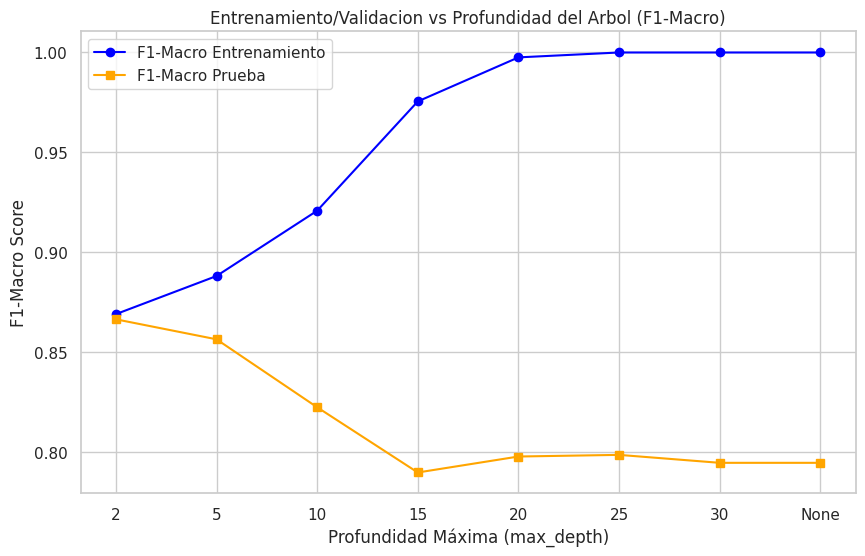

In [26]:
# 3. Gráfica de Errores en Entrenamiento y Prueba
profundidades = [2, 5, 10, 15, 20, 25, 30, None]
train_scores = []
test_scores = []

# StratifiedKFold con 10 particiones y valor aleatorio de 3
cv_grafica = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

for depth in profundidades:
    # Arbol de decisión con valor aleatorio de 7
    clf = DecisionTreeClassifier(max_depth=depth, random_state=7)

    # Evaluar con cross_val_score
    cv_scores = cross_val_score(clf, X, y, cv=cv_grafica, scoring="f1_macro")
    test_scores.append(cv_scores.mean())

    # Evaluar manualmente ya que cross_val_score no da las puntuaciones de entrenamiento
    # Ajustamos el modelo
    clf.fit(X, y)
    y_pred_train = clf.predict(X)
    train_f1 = f1_score(y, y_pred_train, average="macro")
    train_scores.append(train_f1)

# Preparar etiquetas para el eje X
profundidades_str = [str(d) if d is not None else 'None' for d in profundidades]

# Grafica
plt.figure(figsize=(10, 6))
plt.plot(profundidades_str, train_scores, marker='o', label='F1-Macro Entrenamiento', color='blue')
plt.plot(profundidades_str, test_scores, marker='s', label='F1-Macro Prueba', color='orange')
plt.title('Entrenamiento/Validacion vs Profundidad del Arbol (F1-Macro)')
plt.xlabel('Profundidad Máxima (max_depth)')
plt.ylabel('F1-Macro Score')
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# 4. Optimización de hiperparámetros con RandomizedSearchCV (F1 Macro)
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51, 1)),
    'min_samples_split': list(range(2, 21, 1))
}

clf_base = DecisionTreeClassifier(random_state=7)
# StratifiedKFold de 10 (sin partición previa por ser conjunto mediano)
cv_stratified = StratifiedKFold(n_splits=10)

random_search_f1 = RandomizedSearchCV(
    estimator=clf_base,
    param_distributions=param_dist,
    n_iter=5,
    scoring='f1_macro',
    cv=cv_stratified,
    n_jobs=-1,
    random_state=7
)

random_search_f1.fit(X, y)

print("RandomizedSearchCV (F1 Macro)")
print("Mejores hiperparametros:", random_search_f1.best_params_)
print("Best Score:", random_search_f1.best_score_)

RandomizedSearchCV (F1 Macro)
Mejores hiperparametros: {'min_samples_split': 6, 'max_depth': 14, 'criterion': 'gini'}
Best Score: 0.8191478423008831


In [28]:
# 5. Optimización de hiperparámetros con GridSearchCV (F1 Macro)
grid_search_f1 = GridSearchCV(
    estimator=clf_base,
    param_grid=param_dist, # Usamos el mismo diccionario de parámetros
    scoring='f1_macro',
    cv=cv_stratified,
    n_jobs=-1
)

grid_search_f1.fit(X, y)

print("GridSearchCV (F1 Macro)")
print("Mejores hiperparametros:", grid_search_f1.best_params_)
print("Best Score:", grid_search_f1.best_score_)

GridSearchCV (F1 Macro)
Mejores hiperparametros: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 13}
Best Score: 0.8625738971736896


In [29]:
# 6. Optimización de hiperparámetros con RandomizedSearchCV (Accuracy)
random_search_acc = RandomizedSearchCV(
    estimator=clf_base,
    param_distributions=param_dist,
    n_iter=5,
    scoring='accuracy',
    cv=cv_stratified,
    n_jobs=-1,
    random_state=7
)

random_search_acc.fit(X, y)

print("RandomizedSearchCV (Accuracy)")
print("Mejores hiperparametros:", random_search_acc.best_params_)
print("Best Score:", random_search_acc.best_score_)

RandomizedSearchCV (Accuracy)
Mejores hiperparametros: {'min_samples_split': 6, 'max_depth': 14, 'criterion': 'gini'}
Best Score: 0.8236230636833046


In [30]:
# 7. Optimización de hiperparámetros con GridSearchCV (Accuracy)
grid_search_acc = GridSearchCV(
    estimator=clf_base,
    param_grid=param_dist,
    scoring='accuracy',
    cv=cv_stratified,
    n_jobs=-1
)

grid_search_acc.fit(X, y)

print("GridSearchCV (Accuracy)")
print("Mejores hiperparametros:", grid_search_acc.best_params_)
print("Best Score:", grid_search_acc.best_score_)

GridSearchCV (Accuracy)
Mejores hiperparametros: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 13}
Best Score: 0.8641709695926565


¿Cuál método encontró mejores hiperparámetros?
GridSearchCV obtuvo mejores resultados, tanto para F1 Macro como para Accuracy. Esto se debe a que realiza una busqueda exhaustiva de todas las combinaciones definidas, mientras que RandomizedSearchCV evalua solamente una cantidad limitada de combinaciones seleccionadas aleatoriamente. Por esto, GridSearchCV encontro las mejores combinaciones dentro del espacio establecido.

¿Cuál fue más costoso computacionalmente?
GridSearchCV fue mas costoso computacionalmente, ya que evaluo 1748 combinaciones de hiperparametros utilizando 10 particiones de validacion cruzada, lo que representa 17480 entrenamientos por busqueda. En cambio, RandomizedSearchCV realizo solamente 5 combinaciones con 10 particiones, es decir, 50 entrenamientos. Por esta razón, RandomizedSearchCV requiere mucho menos tiempo y recursos computacionales.

¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?
Si. RandomizedSearchCV obtuvo un F1 Macro de 0.81915, mientras que GridSearchCV obtuvo 0.86257. La diferencia se debe principalmente a que RandomizedSearchCV exploro unicamente cinco combinaciones aleatorias, mientras que GridSearchCV evaluo todas las combinaciones disponibles. Esto permitio encontrar una configuración con mejor rendimiento segun la métrica F1 Macro.

¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?
Sí. RandomizedSearchCV obtuvo un Accuracy de 0.82362, mientras que GridSearchCV alcanzo 0.86417. Esto se debe a que GridSearchCV realizo una busqueda exhaustiva, mientras que RandomizedSearchCV evaluo solamente cinco combinaciones aleatorias, por lo que no necesariamente encontro la configuración con mejor Accuracy.

¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?
Sí. En los resultados obtenidos, los hiperparámetros seleccionados fueron iguales para ambas métricas dentro de cada metodo de optimizacion. RandomizedSearchCV encontró criterion='gini', max_depth=14 y min_samples_split=6, mientras que GridSearchCV encontró criterion='entropy', max_depth=6 y min_samples_split=13.

Aunque las metricas Accuracy y F1 Macro evalun aspectos diferentes del rendimiento del modelo, en este experimento ambas seleccionaron las mismas combinaciones de hiperparametros dentro de cada metodo de busqueda.